# mlpath — Getting Started Notebook

This notebook walks through every module of the `mlpath` package:

| Section | What you learn |
|---------|---------------|
| 1. Environment check | Verify all deps are installed |
| 2. Config & parser | Load JSON configs, build CLI parsers |
| 3. DFT interface | Prepare CP2K inputs without running CP2K |
| 4. MLP training prep | Generate MACE training configs |
| 5. MLP evaluation | Run committee inference on fake data |
| 6. Trajectory utilities | Split, select frames, inspect variance |
| 7. Collective variables | Compute CVs on toy structures |
| 8. Workflow state machine | Run a fully mocked active-learning loop |
| 9. Unit tests | Execute the full test suite in-notebook |

> **No CP2K, MACE GPU, or OpenMM is needed for sections 1–7.**  
> Real simulations are started only when you point the workflow at your own config files.


## 1. Environment Check

In [3]:
import importlib, sys

REQUIRED = {
    "numpy":           "Core numerics",
    "ase":             "Atomic Simulation Environment",
    "loguru":          "Structured logging",
    "yaml":            "YAML config files",
    "pytest":          "Test runner",
}

OPTIONAL = {
    "mace":            "MACE interatomic potential (training + inference)",
    "openmm":          "OpenMM MD engine",
    "openmmtools":     "VVVRIntegrator",
    "openmmml":        "MACE-as-OpenMM bridge",
    "openpathsampling":"Transition path sampling framework",
    "MDAnalysis":      "Trajectory analysis",
    "mdtraj":          "Fast trajectory I/O",
    "torch":           "PyTorch (required by MACE)",
    "fairchem":        "FAIRChem foundation models (optional)",
}

print("Required packages")
print("-" * 50)
for pkg, desc in REQUIRED.items():
    try:
        m = importlib.import_module(pkg)
        ver = getattr(m, "__version__", "unknown")
        print(f"  ✅  {pkg:<20} {ver:<12}  {desc}")
    except ImportError:
        print(f"  ❌  {pkg:<20} MISSING       {desc}")

print()
print("Optional packages (needed for real simulations)")
print("-" * 50)
for pkg, desc in OPTIONAL.items():
    try:
        m = importlib.import_module(pkg)
        ver = getattr(m, "__version__", "ok")
        print(f"  ✅  {pkg:<25} {ver:<10}  {desc}")
    except ImportError:
        print(f"  ⚠️   {pkg:<25} not found   {desc}")

Required packages
--------------------------------------------------
  ✅  numpy                2.4.3         Core numerics
  ✅  ase                  3.28.0        Atomic Simulation Environment
  ✅  loguru               0.7.3         Structured logging
  ✅  yaml                 6.0.3         YAML config files
  ✅  pytest               9.0.3         Test runner

Optional packages (needed for real simulations)
--------------------------------------------------
  ⚠️   mace                      not found   MACE interatomic potential (training + inference)
  ✅  openmm                    8.5.1       OpenMM MD engine
  ✅  openmmtools               0.26.0      VVVRIntegrator
  ⚠️   openmmml                  not found   MACE-as-OpenMM bridge
  ⚠️   openpathsampling          not found   Transition path sampling framework
  ⚠️   MDAnalysis                not found   Trajectory analysis
  ✅  mdtraj                    1.11.1      Fast trajectory I/O
  ⚠️   torch                     not found   PyTor

## 2. Config & Parser

Load JSON configs and build argparse-style argument parsers.

In [4]:
import json, tempfile
from pathlib import Path
from util.parser import read_config, print_config, create_parser, global_arguments

# Write a minimal example config to a temp file
example_config = {
    "workdir": ".",
    "max_generations": 5,
    "dft": {"engine": "cp2k", "settings": {"command": "mpirun cp2k"}},
    "mlp": {"E0s": {"1": -13.5, "8": -428.9}, "seeds": [123, 234, 345]},
    "tps": {"config_file": "tps.json"},
    "auto_confirm": {"remove_pause": False, "continue_generation": False},
}

with tempfile.NamedTemporaryFile("w", suffix=".json", delete=False) as f:
    json.dump(example_config, f, indent=2)
    cfg_path = f.name

cfg = read_config(cfg_path)
print("Loaded config:")
print_config(cfg)

Loaded config:
workdir: .
max_generations: 5
dft:
    engine: cp2k
    settings:
        command: mpirun cp2k
mlp:
    E0s:
        1: -13.5
        8: -428.9
    seeds:
        [0]: 123
        [1]: 234
        [2]: 345
tps:
    config_file: tps.json
auto_confirm:
    remove_pause: False
    continue_generation: False


In [5]:
# Build a parser from the shared global argument definitions
parser = create_parser([
    global_arguments["directory"],
    global_arguments["config_file"],
    global_arguments["n_steps"],
    global_arguments["output_path"],
])

# Simulate parsing args (as if called from CLI)
args = parser.parse_args([
    "--directory", ".",
    "--config_file", cfg_path,
    "--n_steps", "100",
])
print("Parsed args:", args)

Parsed args: Namespace(directory=PosixPath('.'), config_file='/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpu_wwygjb.json', n_steps=100, output_path=None)


## 3. DFT Interface

Prepare CP2K input directories **without running CP2K**.

In [6]:
import tempfile
from pathlib import Path
from dft import DFTFactory

workdir = Path(tempfile.mkdtemp())
print(f"Working in: {workdir}")

# Create fake input template
inp = workdir / "cp2k.inp"
inp.write_text("! Fake CP2K input\n&GLOBAL\n  RUN_TYPE ENERGY_FORCE\n&END GLOBAL")

# Create fake coordinate files (real ones would be XYZ files)
for i, content in enumerate(["3\n\nO 0 0 0\nH 1 0 0\nH 0 1 0",
                               "3\n\nO 0 0 0\nH 0 1 0\nH 0 0 1"]):
    (workdir / f"coord_{i}.xyz").write_text(content)

# Instantiate via factory (prepare mode = writes inputs, doesn't run CP2K)
engine = DFTFactory.create(
    "cp2k",
    settings={"command": "mpirun -np 20 cp2k.popt"},
    input_files=[str(inp)],
    reftraj=True,
    run_mode="prepare",
    workdir=str(workdir / "dft_run"),
)

structures = [str(workdir / f"coord_{i}.xyz") for i in range(2)]
engine.run(structures)

# Inspect what was written to disk
dft_dir = Path(engine.workdir)
print("\nFiles prepared:")
for p in sorted(dft_dir.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(dft_dir)}")

# State is persisted to JSON
import json
state = json.loads((dft_dir / "state.json").read_text())
print("\nState file contents:")
for k, v in state.items():
    print(f"  {k}: {v}")

2026-05-06 21:54:44.042 | DEBUG    | dft:run:104 - [CP2K] run() — 2 structure(s).
2026-05-06 21:54:44.044 | DEBUG    | dft:_write_reftraj_inputs:214 - [CP2K] Prepared structure 0 → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5/dft_run/structure_0
2026-05-06 21:54:44.044 | INFO     | dft:_write_reftraj_inputs:215 - [CP2K] Run command for structure 0:
  cd /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5/dft_run/structure_0 && mpirun -np 20 cp2k.popt -i cp2k.inp -o cp2k.out
2026-05-06 21:54:44.046 | DEBUG    | dft:_write_reftraj_inputs:214 - [CP2K] Prepared structure 1 → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5/dft_run/structure_1
2026-05-06 21:54:44.046 | INFO     | dft:_write_reftraj_inputs:215 - [CP2K] Run command for structure 1:
  cd /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5/dft_run/structure_1 && mpirun -np 20 cp2k.popt -i cp2k.inp -o cp2k.out
2026-05-06 21:54:44.054 | INFO     | dft:run:108 - [CP2K] Inputs prepared 

Working in: /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5

Files prepared:
  state.json
  structure_0/PAUSE
  structure_0/coord.xyz
  structure_0/cp2k.inp
  structure_1/PAUSE
  structure_1/coord.xyz
  structure_1/cp2k.inp

State file contents:
  engine: cp2k
  run_mode: prepare
  structure_0: {'status': 0, 'file': '/private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5/coord_0.xyz'}
  structure_1: {'status': 0, 'file': '/private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpeo_1o0q5/coord_1.xyz'}


## 4. MLP Training Preparation

Write MACE training configs for a committee of models.

In [7]:
import tempfile, yaml
from pathlib import Path
from mlp import create_mlp

workdir = Path(tempfile.mkdtemp())

# Create fake train/test data (real use: extxyz files from DFT)
import numpy as np
from ase import Atoms
from ase.io import write

def fake_frame(seed):
    rng = np.random.default_rng(seed)
    a = Atoms("OH2", positions=rng.random((3,3))*3, cell=[10,10,10], pbc=True)
    a.info["energy_cp2k"] = float(rng.standard_normal())
    a.arrays["forces_cp2k"] = rng.standard_normal((3,3))
    return a

train_file = workdir / "train.xyz"
test_file  = workdir / "test.xyz"
write(str(train_file), [fake_frame(i) for i in range(20)])
write(str(test_file),  [fake_frame(i+100) for i in range(5)])

# Isolated atom reference energies (element: eV)
E0s = {1: -13.509, 6: -145.738, 8: -428.893}

mlp = create_mlp("mace", E0s=E0s)

# prepare_only=True → writes YAML + PAUSE, no actual training
result = mlp.train(
    seeds=[123, 234, 345],        # 3 committee members
    output_dir=str(workdir / "runs"),
    train_file=str(train_file),
    test_file=str(test_file),
    prepare_only=True,
    absolute_paths=True,
)

# Inspect generated structure
print("Generated training configs:")
for p in sorted((workdir / "runs").rglob("*.yaml")):
    cfg = yaml.safe_load(p.read_text())
    print(f"  {p.relative_to(workdir)}")
    print(f"    seed={cfg['seed']}, E0s present: {'E0s' in cfg}")

print()
print("PAUSE sentinels (removed when training completes):")
for p in sorted((workdir / "runs").rglob("PAUSE")):
    print(f"  {p.relative_to(workdir)}")

print()
print("After training each committee member externally, copy the .model files")
print("to their respective MACE_models/ folder and remove the PAUSE file.")

2026-05-06 21:55:21.451 | INFO     | mlp:train:210 - HPC training commands:
2026-05-06 21:55:21.452 | INFO     | mlp:train:212 -   cd /private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpgcmmchaq/runs/committee_00 && python -m mace.cli.run_train --config train_seed123.yaml
2026-05-06 21:55:21.452 | INFO     | mlp:train:212 -   cd /private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpgcmmchaq/runs/committee_01 && python -m mace.cli.run_train --config train_seed234.yaml
2026-05-06 21:55:21.452 | INFO     | mlp:train:212 -   cd /private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpgcmmchaq/runs/committee_02 && python -m mace.cli.run_train --config train_seed345.yaml


Generated training configs:
  runs/committee_00/train_seed123.yaml
    seed=123, E0s present: True
  runs/committee_01/train_seed234.yaml
    seed=234, E0s present: True
  runs/committee_02/train_seed345.yaml
    seed=345, E0s present: True

PAUSE sentinels (removed when training completes):
  runs/committee_00/PAUSE
  runs/committee_01/PAUSE
  runs/committee_02/PAUSE

After training each committee member externally, copy the .model files
to their respective MACE_models/ folder and remove the PAUSE file.


## 5. MLP Committee Inference

Run a fake committee of models and inspect uncertainty.

In [8]:
import numpy as np
from ase import Atoms
from unittest.mock import MagicMock
from mlp import MACE_MLP

# Build a test structure
atoms = Atoms("OH2",
    positions=[[0,0,0],[0.96,0,0],[0,0.96,0]],
    cell=[10,10,10], pbc=True)

# Build a fake 3-member committee (replaces real MACE models)
def make_fake_calc(energy, forces):
    c = MagicMock()
    c.get_potential_energy.return_value = energy
    c.get_forces.return_value = np.array(forces)
    return c

rng = np.random.default_rng(42)
committee = [
    make_fake_calc(-45.1, rng.standard_normal((3,3))),
    make_fake_calc(-45.3, rng.standard_normal((3,3))),
    make_fake_calc(-44.9, rng.standard_normal((3,3))),
]

# Evaluate committee — stores variance statistics on atoms in-place
MACE_MLP.evaluate_committee(atoms, committee)

print("Energy predictions per model:")
for i in range(3):
    print(f"  Model {i+1}: {atoms.info[f'energy_m{i+1}']:.4f} eV")

print(f"\nEnergy variance:     {atoms.info['energy_variance']:.6f} eV²")
print(f"Mean force variance: {atoms.info['force_variance']:.6f} (eV/Å)²")
print(f"\nPer-atom force variance:")
for i, v in enumerate(atoms.arrays['force_var_per_atom']):
    print(f"  Atom {i} ({atoms.symbols[i]}): {v:.6f}")

print()
print("Frames with high variance are selected for DFT labelling.")

Energy predictions per model:
  Model 1: -45.1000 eV
  Model 2: -45.3000 eV
  Model 3: -44.9000 eV

Energy variance:     0.026667 eV²
Mean force variance: 0.570549 (eV/Å)²

Per-atom force variance:
  Atom 0 (O): 0.444363
  Atom 1 (H): 1.049789
  Atom 2 (H): 0.217495

Frames with high variance are selected for DFT labelling.


## 6. Trajectory Utilities

Split datasets and select high-uncertainty frames.

In [9]:
import tempfile, numpy as np
from pathlib import Path
from ase import Atoms
from ase.io import write, read
from util.traj_util import train_test_split, select_frames, split_times

workdir = Path(tempfile.mkdtemp())

# ── Build a fake trajectory with committee stats ──────────────────────────
def make_frame(seed):
    rng = np.random.default_rng(seed)
    a = Atoms("OH2", positions=rng.random((3,3))*3, cell=[10,10,10], pbc=True)
    # Simulate committee variance stats
    energies = rng.standard_normal(3)
    forces   = rng.standard_normal((3, 3, 3))
    a.info["energy_variance"]      = float(np.var(energies))
    a.info["force_variance"]       = float(np.var(forces, axis=0).mean())
    a.arrays["forces"]             = forces[0]
    a.arrays["force_var_per_atom"] = np.var(forces, axis=0).mean(axis=1)
    return a

traj_path = workdir / "trajectory.xyz"
write(str(traj_path), [make_frame(i) for i in range(100)])
print(f"Trajectory: 100 frames written to {traj_path.name}")

# ── Train / test split ────────────────────────────────────────────────────
data_path = workdir / "data.xyz"
write(str(data_path), [make_frame(i) for i in range(60)])

train, test = train_test_split(data_path, test_fraction=0.2, seed=42)
print(f"\nTrain/test split (80/20): {len(train)} train, {len(test)} test")

# ── Frame selection ───────────────────────────────────────────────────────
tps_params = {
    "num_select":        20,
    "selection_indices": [30, 50, 70],
    "local_range":       10,
}
selected = select_frames(
    traj_path,
    tps_params,
    out_file=workdir / "selected.xyz",
)
print(f"\nSelected {len(selected)} high-uncertainty frames for DFT labelling")

# Show variance distribution of selected frames
e_vars = [f.info["energy_variance"] for f in selected]
print(f"  Energy variance: min={min(e_vars):.4f}  max={max(e_vars):.4f}  mean={np.mean(e_vars):.4f}")

# ── Split for parallel DFT jobs ───────────────────────────────────────────
parts = split_times(workdir / "selected.xyz", split=4, seed=0)
print(f"\nSplit into {len(parts)} segments for parallel CP2K jobs:")
for p in parts:
    n = len(read(str(p), ":"))
    print(f"  {p.name}: {n} frames")

2026-05-06 21:55:37.696 | INFO     | util.traj_util:train_test_split:63 - Split 60 frames → 48 train, 12 test.
2026-05-06 21:55:37.725 | INFO     | util.traj_util:select_frames:163 - Selected 20 frames → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmp_wxm522n/selected.xyz
2026-05-06 21:55:37.733 | INFO     | util.traj_util:split_times:209 - Segment 1/4: 5 frames → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmp_wxm522n/selected_part1.xyz
2026-05-06 21:55:37.735 | INFO     | util.traj_util:split_times:209 - Segment 2/4: 5 frames → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmp_wxm522n/selected_part2.xyz
2026-05-06 21:55:37.736 | INFO     | util.traj_util:split_times:209 - Segment 3/4: 5 frames → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmp_wxm522n/selected_part3.xyz
2026-05-06 21:55:37.738 | INFO     | util.traj_util:split_times:209 - Segment 4/4: 5 frames → /var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmp_wxm522n/selected_part4.xyz


Trajectory: 100 frames written to trajectory.xyz

Train/test split (80/20): 48 train, 12 test

Selected 20 high-uncertainty frames for DFT labelling
  Energy variance: min=0.0414  max=4.0273  mean=1.2091

Split into 4 segments for parallel CP2K jobs:
  selected_part1.xyz: 5 frames
  selected_part2.xyz: 5 frames
  selected_part3.xyz: 5 frames
  selected_part4.xyz: 5 frames


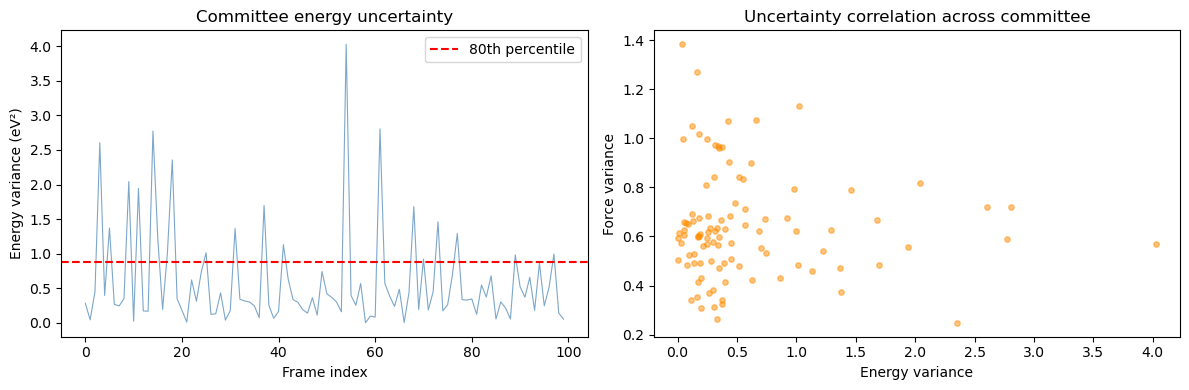

High-variance frames (top right) are prioritised for DFT labelling.


In [10]:
# ── Visualise frame uncertainty ───────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np
from ase.io import read

all_frames = read(str(traj_path), ":")
e_var = np.array([f.info["energy_variance"] for f in all_frames])
f_var = np.array([f.info["force_variance"]  for f in all_frames])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(e_var, alpha=0.7, lw=0.8, color="steelblue")
axes[0].axhline(np.percentile(e_var, 80), ls="--", color="red", label="80th percentile")
axes[0].set_xlabel("Frame index"); axes[0].set_ylabel("Energy variance (eV²)")
axes[0].set_title("Committee energy uncertainty"); axes[0].legend()

axes[1].scatter(e_var, f_var, alpha=0.5, s=15, color="darkorange")
axes[1].set_xlabel("Energy variance"); axes[1].set_ylabel("Force variance")
axes[1].set_title("Uncertainty correlation across committee")

plt.tight_layout()
plt.show()
print("High-variance frames (top right) are prioritised for DFT labelling.")

## 7. Collective Variables

Compute CV values on toy structures (no OpenMM/OPS needed).

In [13]:
import numpy as np
from util.cv import CV

# ── Snapshot stub (mimics an OPS snapshot) ───────────────────────────────
class Snap:
    def __init__(self, positions):
        self.xyz = np.array(positions, dtype=float)

# ── bond: COM distance between two groups ───────────────────────────────
water = Snap([[0, 0, 0],   # O
              [0.96, 0, 0], # H1
              [0, 0.96, 0]])# H2

d_OH1 = CV.bond(water, group_A_atoms=np.array([0]), group_B_atoms=np.array([1]),
                 type=0, axis=-1)
print(f"O–H1 distance:  {d_OH1:.4f} (units match positions, here Å)")

# ── CN: coordination number ──────────────────────────────────────────────
# Two oxygen atoms, one hydrogen — CN of O1 coordinated to H
molecule = Snap([[0, 0, 0],   # O1
                 [0.1, 0, 0], # H  (0.1 nm = 1 Å ≈ O-H bond)
                 [1.0, 0, 0]])# O2 (far away)

cn = CV.CN(molecule,
           group_A_atoms=np.array([0]),
           group_B_atoms=np.array([1, 2]),
           d0=1.5, n=6, m=12)
print(f"Coordination number (O1): {cn:.4f}  (expect ~1 for one close H)")

# ── bondfunction: linear combination of distances ────────────────────────
s = Snap([[0,0,0],[1,0,0],[0,0,0],[3,0,0]])
bfn = CV.bondfunction(s,
    group_A_atoms=np.array([0]), group_B_atoms=np.array([1]),
    group_C_atoms=np.array([2]), group_D_atoms=np.array([3]),
    coeff=-1)
print(f"Bond function (d_AB - d_CD): {bfn:.4f}  (expect 1 - 3 = -2)")

# ── bond_plane_angle ─────────────────────────────────────────────────────
vertical = Snap([[0,0,1],[0,0,0]])  # vector pointing straight up
angle = CV.bond_plane_angle(vertical, np.array([0]), np.array([1]), axis=2)
print(f"Angle to XY plane (vertical vector): {angle:.1f}°  (expect ±90°)")

O–H1 distance:  0.9600 (units match positions, here Å)
Coordination number (O1): 0.9193  (expect ~1 for one close H)
Bond function (d_AB - d_CD): -2.0000  (expect 1 - 3 = -2)
Angle to XY plane (vertical vector): -90.0°  (expect ±90°)


## 8. Workflow State Machine

Run a fully mocked active-learning loop — no real simulations needed.

In [14]:
import json, tempfile
from pathlib import Path
from unittest.mock import patch

from workflow import (
    Workflow, WorkflowConfig, WorkflowState,
    DFTStage, MLPStage, TPSStage, FrameSelectStage,
    StageName, StageStatus,
)

# ── Write a minimal workflow config ──────────────────────────────────────
workdir = Path(tempfile.mkdtemp())
(workdir / "init").mkdir()

cfg_data = {
    "workdir": str(workdir),
    "max_generations": 3,
    "structures": ["init/coord.xyz"],
    "top_file": "top.pdb",
    "dft": {"engine": "cp2k", "input_files": ["cp2k.inp"],
            "settings": {"command": "cp2k"}, "workdir": "single_reftraj"},
    "mlp": {"E0s": {"1": -13.5, "8": -428.9}, "seeds": [1, 2], "test_fraction": 0.25},
    "tps": {"config_file": "tps.json"},
    "auto_confirm": {
        "remove_pause":        True,  # auto-remove PAUSE files
        "continue_generation": True,  # auto-advance generations
        "run_smd":             False,
    },
}
cfg_path = workdir / "workflow.json"
cfg_path.write_text(json.dumps(cfg_data, indent=2))

# ── Run with all stage _run() methods returning True (instant success) ───
with patch.object(DFTStage,         "_run", return_value=True), \
     patch.object(MLPStage,         "_run", return_value=True), \
     patch.object(TPSStage,         "_run", return_value=True), \
     patch.object(FrameSelectStage, "_run", return_value=True):

    wf = Workflow(config_path=str(cfg_path))
    wf.run()

# ── Inspect persisted state ───────────────────────────────────────────────
state_file = workdir / "workflow_state.json"
state = json.loads(state_file.read_text())

print("Workflow completed!")
print(f"  Final generation: {state['current_generation']}")
print()
print("Per-generation stage statuses:")
for gen_idx, gen_data in sorted(state["generations"].items(), key=lambda x: int(x[0])):
    print(f"  Generation {gen_idx}:")
    for stage, info in gen_data["stages"].items():
        symbol = "✅" if info["status"] == "done" else "❌"
        print(f"    {symbol} {stage}: {info['status']}")

2026-05-06 21:58:33.817 | INFO     | workflow:run:772 - Workflow starting | workdir=/private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmphvvbt0ca | max_gen=3 | start_gen=0
2026-05-06 21:58:33.818 | INFO     | workflow:run:784 - ============================================================
2026-05-06 21:58:33.819 | INFO     | workflow:run:785 -   Generation 0
2026-05-06 21:58:33.819 | INFO     | workflow:run:786 - ============================================================
2026-05-06 21:58:33.820 | DEBUG    | workflow:_save_state:765 - State saved → /private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmphvvbt0ca/workflow_state.json
2026-05-06 21:58:33.821 | INFO     | workflow:run:255 - [Gen 0][dft] Starting.
2026-05-06 21:58:33.821 | INFO     | workflow:run:267 - [Gen 0][dft] Done.
2026-05-06 21:58:33.822 | INFO     | workflow:run:255 - [Gen 0][mlp] Starting.
2026-05-06 21:58:33.822 | INFO     | workflow:run:267 - [Gen 0][mlp] Done.
2026-05-06 21:58:33.823 | INFO     | work

Workflow completed!
  Final generation: 3

Per-generation stage statuses:
  Generation 0:
    ✅ dft: done
    ✅ mlp: done
    ✅ tps: done
    ✅ frame_select: done
  Generation 1:
    ✅ dft: done
    ✅ mlp: done
    ✅ tps: done
    ✅ frame_select: done
  Generation 2:
    ✅ dft: done
    ✅ mlp: done
    ✅ tps: done
    ✅ frame_select: done


In [15]:
# ── Demo: resume after a blocked generation ──────────────────────────────
import json, tempfile
from pathlib import Path
from unittest.mock import patch
from workflow import Workflow, DFTStage, MLPStage, TPSStage, FrameSelectStage

workdir2 = Path(tempfile.mkdtemp())
(workdir2 / "init").mkdir()
cfg_path2 = workdir2 / "workflow.json"
cfg_path2.write_text(json.dumps({**cfg_data, "workdir": str(workdir2)}, indent=2))

call_counts = {"dft": 0, "mlp": 0}

def dft_that_blocks(self):
    call_counts["dft"] += 1
    return call_counts["dft"] >= 2   # fails first time, succeeds second

print("=== First run (DFT blocked on gen 0) ===")
with patch.object(DFTStage, "_run", dft_that_blocks), \
     patch.object(MLPStage, "_run", return_value=True), \
     patch.object(TPSStage, "_run", return_value=True), \
     patch.object(FrameSelectStage, "_run", return_value=True):
    wf = Workflow(config_path=str(cfg_path2))
    wf.run()

state = json.loads((workdir2 / "workflow_state.json").read_text())
print(f"  Current generation: {state['current_generation']}")
print(f"  Gen 0 DFT status:   {state['generations']['0']['stages']['dft']['status']}")

print()
print("=== Second run (resume — DFT now succeeds) ===")
with patch.object(DFTStage, "_run", dft_that_blocks), \
     patch.object(MLPStage, "_run", return_value=True), \
     patch.object(TPSStage, "_run", return_value=True), \
     patch.object(FrameSelectStage, "_run", return_value=True):
    wf2 = Workflow(config_path=str(cfg_path2))
    wf2.run()

state = json.loads((workdir2 / "workflow_state.json").read_text())
print(f"  Resumed from gen:   {state['current_generation'] - 1}")
print(f"  Gen 0 DFT status:   {state['generations']['0']['stages']['dft']['status']}")
print(f"  Gen 0 done:         {state['generations']['0']['done']}")

2026-05-06 21:58:40.226 | INFO     | workflow:run:772 - Workflow starting | workdir=/private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpn0a2bytd | max_gen=3 | start_gen=0
2026-05-06 21:58:40.227 | INFO     | workflow:run:784 - ============================================================
2026-05-06 21:58:40.228 | INFO     | workflow:run:785 -   Generation 0
2026-05-06 21:58:40.228 | INFO     | workflow:run:786 - ============================================================
2026-05-06 21:58:40.229 | DEBUG    | workflow:_save_state:765 - State saved → /private/var/folders/vm/cnsxwt2d0yq3gcc0h5pb71s00000gn/T/tmpn0a2bytd/workflow_state.json
2026-05-06 21:58:40.230 | INFO     | workflow:run:255 - [Gen 0][dft] Starting.
2026-05-06 21:58:40.231 | INFO     | workflow:run:273 - [Gen 0][dft] Blocked; manual step needed.
2026-05-06 21:58:40.232 | INFO     | workflow:run:702 - [Gen 0] Halted at 'dft'. Rerun after completing the required manual step.
2026-05-06 21:58:40.233 | DEBUG    | workf

=== First run (DFT blocked on gen 0) ===
  Current generation: 0
  Gen 0 DFT status:   pending

=== Second run (resume — DFT now succeeds) ===
  Resumed from gen:   2
  Gen 0 DFT status:   done
  Gen 0 done:         True


## 9. Full Test Suite

Run all 139 unit tests directly from this notebook.

In [18]:
import subprocess, sys

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v", "--tb=short", "--no-header"],
    capture_output=True, text=True
)
print(result.stdout)
if result.returncode != 0:
    print("STDERR:", result.stderr)


STDERR: ImportError while loading conftest '/Users/ashiquel/mnt_drive/8/work/rik/5/MACE-TPS/path/conftest.py'.
__init__.py:19: in <module>
    from .tps      import TPS_setup, Sampler
tps.py:53: in <module>
    from openmmml import MLPotential
E   ModuleNotFoundError: No module named 'openmmml'



## Real-world Usage

Once your environment is set up with real MACE, OpenMM, and CP2K:

```python
from workflow import Workflow

wf = Workflow(config_path="workflow.json")
wf.run()
```

Or from the command line:

```bash
# Fresh run
python workflow.py --config workflow.json

# Resume at a specific generation
python workflow.py --config workflow.json --gen 2

# Run only one stage
python workflow.py --config workflow.json --stage mlp

# Run tests
pytest tests/ -v
```

See `workflow_config_example.json` for a fully annotated config template.
